<a href="https://colab.research.google.com/github/Aryanshh/CSET343/blob/main/Lab10_1758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Cell 1: Install Required Libraries

!pip install wfdb numpy pandas matplotlib seaborn scipy scikit-learn tensorflow -q


In [2]:

# Cell 2: Import Required Libraries

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import wfdb
import tensorflow as tf

from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    SimpleRNN, LSTM, GRU, Dense, Dropout, Input
)
from tensorflow.keras.callbacks import EarlyStopping

# Set random seeds
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

# Cell 3: Download MIT-BIH Arrhythmia Database

DATA_DIR = "/content/mitbih"

os.makedirs(DATA_DIR, exist_ok=True)

wfdb.dl_database("mitdb", dl_dir=DATA_DIR)

print("MIT-BIH database downloaded successfully!")


Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

In [4]:

# Cell 4: Explore Dataset

record_files = sorted([
    f for f in os.listdir(DATA_DIR)
    if f.endswith(".dat")
])

record_names = [
    os.path.splitext(f)[0] for f in record_files
]

print("Total Records:", len(record_names))
print("\nAvailable Records:")
print(record_names)

# Read one ECG recording
sample_record = wfdb.rdrecord(
    os.path.join(DATA_DIR, record_names[0])
)

print("\nSignal Shape:", sample_record.p_signal.shape)
print("Sampling Frequency:", sample_record.fs)
print("Signal Channels:", sample_record.sig_name)


Total Records: 48

Available Records:
['100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '111', '112', '113', '114', '115', '116', '117', '118', '119', '121', '122', '123', '124', '200', '201', '202', '203', '205', '207', '208', '209', '210', '212', '213', '214', '215', '217', '219', '220', '221', '222', '223', '228', '230', '231', '232', '233', '234']

Signal Shape: (650000, 2)
Sampling Frequency: 360
Signal Channels: ['MLII', 'V5']


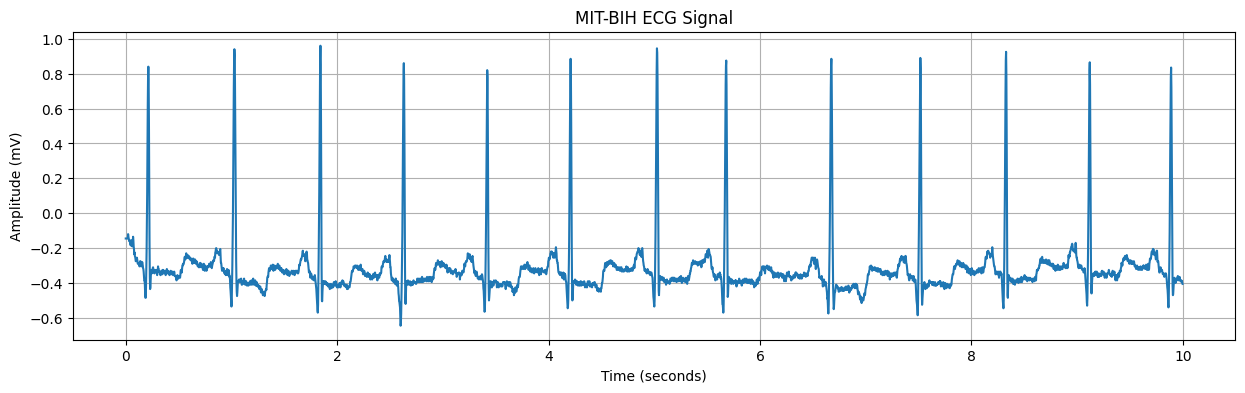

In [5]:

# Cell 5: Visualize ECG Signal

record = wfdb.rdrecord(
    os.path.join(DATA_DIR, record_names[0])
)

ecg_signal = record.p_signal[:, 0]
fs = record.fs

time = np.arange(len(ecg_signal)) / fs

plt.figure(figsize=(15, 4))

plt.plot(time[:3600], ecg_signal[:3600])

plt.title("MIT-BIH ECG Signal")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid()

plt.show()


In [6]:

# Cell 6: Define AAMI Classes and Bandpass Filter

# AAMI beat classification
AAMI_CLASSES = {
    "N": ["N", "L", "R", "e", "j"],
    "S": ["A", "a", "J", "S"],
    "V": ["V", "E"],
    "F": ["F"],
    "Q": ["/", "f", "Q", "?"]
}

class_to_label = {
    "N": 0,
    "S": 1,
    "V": 2,
    "F": 3,
    "Q": 4
}

symbol_to_label = {}

for class_name, symbols in AAMI_CLASSES.items():
    for symbol in symbols:
        symbol_to_label[symbol] = class_to_label[class_name]

class_names = ["N", "S", "V", "F", "Q"]

# Remove paced records
paced_records = ["102", "104", "107", "217"]

# Bandpass filter: 0.5–40 Hz
def bandpass_filter(signal, fs=360):

    sos = butter(
        4,
        [0.5, 40],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    return sosfiltfilt(sos, signal)

print("AAMI classes:", class_to_label)
print("Bandpass filter defined successfully!")


AAMI classes: {'N': 0, 'S': 1, 'V': 2, 'F': 3, 'Q': 4}
Bandpass filter defined successfully!


In [7]:

# Cell 7: Extract Heartbeat Segments

X = []
y = []
groups = []

# Beat window parameters
BEFORE = 128
AFTER = 128

for record_name in record_names:

    # Skip paced records
    if record_name in paced_records:
        continue

    print("Processing Record:", record_name)

    try:

        # Read ECG signal
        record = wfdb.rdrecord(
            os.path.join(DATA_DIR, record_name)
        )

        signal = record.p_signal[:, 0]
        fs = record.fs

        # Filter ECG signal
        filtered_signal = bandpass_filter(signal, fs)

        # Read beat annotations
        annotation = wfdb.rdann(
            os.path.join(DATA_DIR, record_name),
            "atr"
        )

        # Extract annotated beats
        for sample, symbol in zip(
            annotation.sample,
            annotation.symbol
        ):

            # Ignore non-beat annotations
            if symbol not in symbol_to_label:
                continue

            start = sample - BEFORE
            end = sample + AFTER

            # Check window boundaries
            if start < 0 or end > len(filtered_signal):
                continue

            beat = filtered_signal[start:end]

            # Normalize each beat
            mean = np.mean(beat)
            std = np.std(beat)

            if std < 1e-8:
                continue

            beat = (beat - mean) / std

            X.append(beat)
            y.append(symbol_to_label[symbol])
            groups.append(record_name)

    except Exception as e:
        print("Error processing", record_name, ":", e)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int32)
groups = np.array(groups)

print("\nHeartbeat extraction completed!")
print("X Shape:", X.shape)
print("Y Shape:", y.shape)
print("Total Heartbeats:", len(y))


Processing Record: 100
Processing Record: 101
Processing Record: 103
Processing Record: 105
Processing Record: 106
Processing Record: 108
Processing Record: 109
Processing Record: 111
Processing Record: 112
Processing Record: 113
Processing Record: 114
Processing Record: 115
Processing Record: 116
Processing Record: 117
Processing Record: 118
Processing Record: 119
Processing Record: 121
Processing Record: 122
Processing Record: 123
Processing Record: 124
Processing Record: 200
Processing Record: 201
Processing Record: 202
Processing Record: 203
Processing Record: 205
Processing Record: 207
Processing Record: 208
Processing Record: 209
Processing Record: 210
Processing Record: 212
Processing Record: 213
Processing Record: 214
Processing Record: 215
Processing Record: 219
Processing Record: 220
Processing Record: 221
Processing Record: 222
Processing Record: 223
Processing Record: 228
Processing Record: 230
Processing Record: 231
Processing Record: 232
Processing Record: 233
Processing 

  Class  Count
0     N  90087
1     S   2781
2     V   7008
3     F    802
4     Q     15


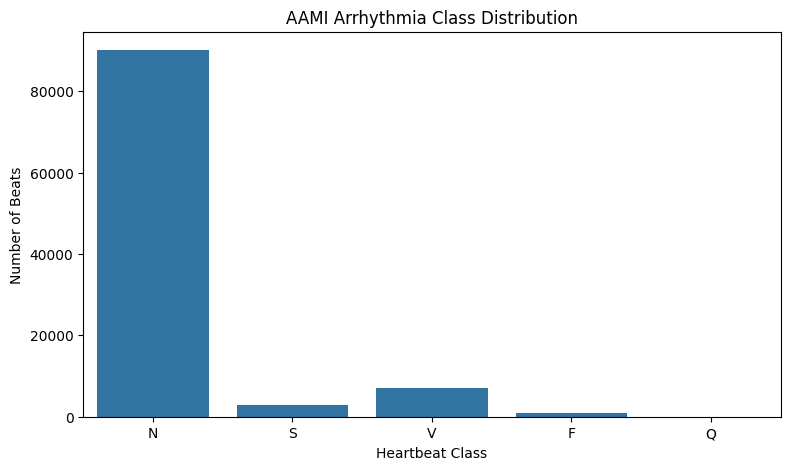

In [8]:

# Cell 8: Check AAMI Class Distribution

class_counts = pd.Series(y).value_counts().sort_index()

distribution = pd.DataFrame({
    "Class": class_names,
    "Count": [
        np.sum(y == i) for i in range(5)
    ]
})

print(distribution)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=distribution,
    x="Class",
    y="Count"
)

plt.title("AAMI Arrhythmia Class Distribution")
plt.xlabel("Heartbeat Class")
plt.ylabel("Number of Beats")

plt.show()


In [9]:

# Cell 9: Patient-Wise Train, Validation and Test Split

# Treat records 201 and 202 as belonging to
# the same patient group.
patient_groups = np.array([
    "201_202" if g in ["201", "202"] else g
    for g in groups
])

# First split: 80% training, 20% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=SEED
)

train_idx, temp_idx = next(
    split1.split(X, y, groups=patient_groups)
)

# Second split: divide temporary into validation and test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED
)

val_relative, test_relative = next(
    split2.split(
        X[temp_idx],
        y[temp_idx],
        groups=patient_groups[temp_idx]
    )
)

val_idx = temp_idx[val_relative]
test_idx = temp_idx[test_relative]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nUnique patient groups:")
print(
    len(set(patient_groups[train_idx])),
    len(set(patient_groups[val_idx])),
    len(set(patient_groups[test_idx]))
)

assert not (
    set(patient_groups[train_idx]) &
    set(patient_groups[val_idx])
)

assert not (
    set(patient_groups[train_idx]) &
    set(patient_groups[test_idx])
)

assert not (
    set(patient_groups[val_idx]) &
    set(patient_groups[test_idx])
)

print("\nPatient-wise split completed successfully!")


Training samples: 80250
Validation samples: 9828
Testing samples: 10615

Unique patient groups:
34 4 5

Patient-wise split completed successfully!


In [10]:

# Cell 10: Reshape Data and Calculate Class Weights

# RNN, LSTM and GRU require 3D input:
# (samples, timesteps, features)

X_train = X_train.reshape(
    X_train.shape[0], X_train.shape[1], 1
)

X_val = X_val.reshape(
    X_val.shape[0], X_val.shape[1], 1
)

X_test = X_test.reshape(
    X_test.shape[0], X_test.shape[1], 1
)

# Calculate class weights using training data
present_classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=present_classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(present_classes, weights)
}

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

print("\nClass Weights:")
print(class_weights)


Training Shape: (80250, 256, 1)
Validation Shape: (9828, 256, 1)
Testing Shape: (10615, 256, 1)

Class Weights:
{0: 0.21900798253394282, 1: 6.19212962962963, 2: 4.06947261663286, 3: 38.58173076923077, 4: 1234.6153846153845}


In [11]:

# Cell 11: Build RNN, LSTM and GRU Models

def build_model(model_type):

    model = Sequential()

    model.add(
        Input(shape=(256, 1))
    )

    if model_type == "RNN":

        model.add(
            SimpleRNN(64, return_sequences=False)
        )

    elif model_type == "LSTM":

        model.add(
            LSTM(64, return_sequences=False)
        )

    elif model_type == "GRU":

        model.add(
            GRU(64, return_sequences=False)
        )

    model.add(Dropout(0.3))

    model.add(Dense(32, activation="relu"))

    model.add(Dense(5, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# Build all three models
rnn_model = build_model("RNN")
lstm_model = build_model("LSTM")
gru_model = build_model("GRU")

print("RNN Model:")
rnn_model.summary()

print("\nLSTM Model:")
lstm_model.summary()

print("\nGRU Model:")
gru_model.summary()


RNN Model:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,469 (25.27 KB)

 Trainable params: 6,469 (25.27 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,109 (59.02 KB)

 Trainable params: 15,109 (59.02 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:

# Cell 12: Train RNN Model

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

print("RNN Training Completed!")


Epoch 1/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 45s 69ms/step - accuracy: 0.2350 - loss: 1.8926 - val_accuracy: 0.2110 - val_loss: 1.5776
Epoch 2/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 41s 66ms/step - accuracy: 0.1929 - loss: 1.7094 - val_accuracy: 2.0350e-04 - val_loss: 1.7856
Epoch 3/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 83s 67ms/step - accuracy: 0.1921 - loss: 1.6887 - val_accuracy: 5.0875e-04 - val_loss: 1.7391
Epoch 4/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 45s 72ms/step - accuracy: 0.1724 - loss: 1.6653 - val_accuracy: 6.1050e-04 - val_loss: 1.6670
Epoch 5/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 44s 70ms/step - accuracy: 0.2505 - loss: 1.6446 - val_accuracy: 0.0128 - val_loss: 1.5987
Epoch 6/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 79s 65ms/step - accuracy: 0.2223 - loss: 1.5978 - val_accuracy: 0.0414 - val_loss: 1.6016
RNN Training Completed!


In [13]:

# Cell 13: Train LSTM Model

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

print("LSTM Training Completed!")


Epoch 1/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 210s 331ms/step - accuracy: 0.2136 - loss: 1.8017 - val_accuracy: 0.0914 - val_loss: 1.5702
Epoch 2/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 214s 342ms/step - accuracy: 0.1514 - loss: 1.5229 - val_accuracy: 0.0119 - val_loss: 1.7059
Epoch 3/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 258s 335ms/step - accuracy: 0.0942 - loss: 1.5118 - val_accuracy: 0.1422 - val_loss: 1.5925
Epoch 4/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 213s 340ms/step - accuracy: 0.1867 - loss: 1.4889 - val_accuracy: 0.0609 - val_loss: 1.6099
Epoch 5/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 265s 345ms/step - accuracy: 0.1435 - loss: 1.4551 - val_accuracy: 0.0370 - val_loss: 1.6986
Epoch 6/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 208s 332ms/step - accuracy: 0.1363 - loss: 1.3809 - val_accuracy: 0.0332 - val_loss: 1.7053
LSTM Training Completed!


In [ ]:

# Cell 14: Train GRU Model

gru_history = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

print("GRU Training Completed!")


Epoch 1/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 263s 417ms/step - accuracy: 0.2460 - loss: 1.7002 - val_accuracy: 0.0919 - val_loss: 1.5790
Epoch 2/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 257s 410ms/step - accuracy: 0.2416 - loss: 1.5076 - val_accuracy: 0.0307 - val_loss: 1.6913
Epoch 3/30
627/627 ━━━━━━━━━━━━━━━━━━━━ 261s 416ms/step - accuracy: 0.2062 - loss: 1.3797 - val_accuracy: 0.0265 - val_loss: 1.7237
Epoch 4/30
 44/627 ━━━━━━━━━━━━━━━━━━━━ 3:42 382ms/step - accuracy: 0.1137 - loss: 1.1294

In [ ]:

# Cell 15: Plot Training and Validation Accuracy

histories = {
    "RNN": rnn_history,
    "LSTM": lstm_history,
    "GRU": gru_history
}

plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history["accuracy"],
        label=name + " Training"
    )

    plt.plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=name + " Validation"
    )

plt.title("RNN vs LSTM vs GRU Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()


In [ ]:

# Cell 16: Plot Training and Validation Loss

plt.figure(figsize=(12, 6))

for name, history in histories.items():

    plt.plot(
        history.history["loss"],
        label=name + " Training"
    )

    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=name + " Validation"
    )

plt.title("RNN vs LSTM vs GRU Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()


In [ ]:

# Cell 17: Evaluate Models on Test Dataset

models = {
    "RNN": rnn_model,
    "LSTM": lstm_model,
    "GRU": gru_model
}

results = {}
predictions = {}

for name, model in models.items():

    print("\nEvaluating", name)

    y_prob = model.predict(X_test, verbose=0)

    y_pred = np.argmax(y_prob, axis=1)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        labels=[0, 1, 2, 3, 4],
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        labels=[0, 1, 2, 3, 4],
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        labels=[0, 1, 2, 3, 4],
        average="macro",
        zero_division=0
    )

    results[name] = {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    }

    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)


In [ ]:

# Cell 18: Classification Reports

for name in models.keys():

    print("\n================================")
    print(name, "Classification Report")
    print("================================")

    print(
        classification_report(
            y_test,
            predictions[name],
            labels=[0, 1, 2, 3, 4],
            target_names=class_names,
            zero_division=0
        )
    )


In [ ]:

# Cell 19: Plot Confusion Matrices

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5)
)

for ax, name in zip(axes, models.keys()):

    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1, 2, 3, 4]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_title(name + " Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


In [ ]:

# Cell 20: Compare RNN, LSTM and GRU Performance

results_df = pd.DataFrame(results).T

print("Model Performance Comparison:")
print(results_df)

# Plot comparison
results_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of RNN, LSTM and GRU")
plt.xlabel("Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")

plt.show()


In [ ]:

# Cell 21: Identify Best Performing Model

best_model_name = results_df["F1 Score"].idxmax()

best_f1_score = results_df.loc[
    best_model_name, "F1 Score"
]

print("Best Model:", best_model_name)
print("Best F1 Score:", best_f1_score)

print("\nComplete Performance:")
print(results_df)

if best_model_name == "RNN":
    best_model = rnn_model

elif best_model_name == "LSTM":
    best_model = lstm_model

else:
    best_model = gru_model

print("\nBest model selected successfully!")


In [ ]:

# Cell 22: Save Trained Models

rnn_model.save("/content/RNN_model.keras")
lstm_model.save("/content/LSTM_model.keras")
gru_model.save("/content/GRU_model.keras")

best_model.save("/content/Best_Arrhythmia_Model.keras")

print("All models saved successfully!")
